In [1]:
# First install the extendedjetpy package with: python setup.py install
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import JetCode # CHANGE TO extendedjetpy CUANDO ANDE BIEN!!!!
import time

In [2]:
# Define the SED function
def model_sed(E, z, sigma0, Lj, z0, a_inj):
    #CAMBIARLO A keyword arguments! Menos chances de errores
    """
    Total (Synchrotron + SSC) SED calculated at photon energies in the vector E
    at integration heights z.
    The available free parameters are: 
    - sigma0 (initial magnetization) 
    - Lj (jet luminosity)
    - z0 (height at jet base)
    - a_inj (power injected as Q(z) \propto z^-a_inj)
    """
    # CHANGE TO extendedjetpy CUANDO ANDE BIEN!!!!
    
    # This routine returns m_data_max values, as defined in global.f90
    fit_values = JetCode.sed_model(sigma0, Lj, z0, a_inj, E, z) 
    
    # The only useful values are the first ones up to the number of points in E
    return( fit_values[:len(E)]) 

def model_syn(E, z, sigma0, Lj, z0, a_inj):
    #CAMBIARLO A keyword arguments! Menos chances de errores
    """
    Total (Synchrotron + SSC) SED calculated at photon energies in the vector E
    at integration heights z.
    The available free parameters are: 
    - sigma0 (initial magnetization) 
    - Lj (jet luminosity)
    - z0 (height at jet base)
    - a_inj (power injected as Q(z) \propto z^-(1+a_inj) )
    """
    # CHANGE TO extendedjetpy CUANDO ANDE BIEN!!!!
    
    # This routine returns m_data_max values, as defined in global.f90
    fit_values = JetCode.syn_model(sigma0, Lj, a_inj, E) 
    
    # The only useful values are the first ones up to the number of points in E
    return( fit_values[:len(E)])       

<>:4: SyntaxWarning: invalid escape sequence '\p'
<>:23: SyntaxWarning: invalid escape sequence '\p'
<>:4: SyntaxWarning: invalid escape sequence '\p'
<>:23: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_19897/1261224588.py:4: SyntaxWarning: invalid escape sequence '\p'
  """
/tmp/ipykernel_19897/1261224588.py:23: SyntaxWarning: invalid escape sequence '\p'
  """


In [3]:
# Sthetics for plots
nice_fonts = {
        # Use LaTeX to write all text
        "text.usetex": True,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 18,
        "font.size": 18,
        "axes.linewidth":1,
        "axes.titlesize":16,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 12,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "xtick.major.size": 5,     # major tick size in points
        "xtick.minor.size": 5,       # minor tick size in points
        "xtick.major.width": 1.4,     # major tick width in points
        "xtick.minor.width": 1.4,     # minor tick width in points
}
matplotlib.rcParams.update(nice_fonts)

In [4]:
#Constants
mJy = 1.0e-26
dist = 3.8*3.0856e24  # Distance to the source = 16.8 Mpc
h = 6.6260755e-27      # erg s
eV = 1.602176e-12      # eV to erg
a = 4.0*np.pi*dist**2  # Flux dilution factor
M_BH = 6.5e9           # Black hole mass [Msun] (EHT+2018?)
R_g = 1.477e5*M_BH     # Gravitational radius (M_BH [Msun])

# Default model parameters
sigma0_def = 1e1
Lj_def = 1.1e42#1e43
z0_def = 250.0*R_g #10.0*R_g
a_inj_def = 0.2#0.5

# Define the energy range for the SED
E_min = 3.3e-7 * eV #Aprox 100 MHz
E_max = 3.3e7 * eV
n_points = 80
E = np.geomspace(E_min, E_max, n_points)
z = np.geomspace(5*R_g, 100*R_g, n_points)

# Explore sigma0 variations

In [5]:
# Make a list with the values of fB 
sigma0s = [2e0, 10e0, 50e0,100e0] 

# Calculate the SED for each sigma0 value (fixing default parameters)
SEDs_sigma = []
for sigma0 in sigma0s:
    print(f'{sigma0=}')
    time.sleep(1)
    #SED = model_sed(E, z, sigma0, Lj_def, z0_def, a_inj_def)
    SED = model_syn(E, z, sigma0, Lj_def, z0_def, a_inj_def)
    time.sleep(2)
    SEDs_sigma.append(SED)

sigma0=2.0
sigma0=10.0
sigma0=50.0
sigma0=100.0


In [6]:
matplotlib.rcParams['text.usetex'] = False

### Grafico E*L [erg s-1] vs E [eV]

/tmp/ipykernel_6987/4072430145.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('copper_r', n)
/tmp/ipykernel_6987/4072430145.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='best')


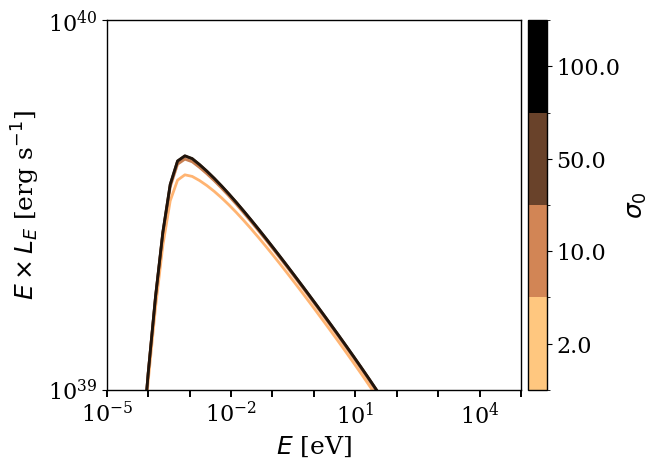

In [7]:
# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = len(sigma0s)
color_vector = np.linspace(0.1, 0.9, n)
colors = plt.cm.copper_r(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('copper_r', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Set labels
plt.title('')
plt.setp(ax, xlabel=r"$E$ [eV]")
plt.setp(ax, ylabel=r"$E \times L_E$ [erg s$^{-1}$]")

# Set plot scales
xmin, xmax = 1e-5,1e5#E_min/eV, E_max/eV
ymin, ymax = 1e39, 1e40
plt.xlim(xmin, xmax)
plt.ylim(ymin, ymax)

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(E/eV, E*SEDs_sigma[i]*a, ls='-', color=colors[i], linewidth=2, label='', zorder=1)

plt.legend(loc='best')
ax.loglog() 

cbar = fig.colorbar(sm, ax=ax, ticks=c, label=r"$\sigma_0$", pad=0.015)
cbar.ax.set_yticklabels(sigma0s)  # vertically oriented colorbar

# Set xticks
num = int(np.log10(xmax/xmin))
x_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = num//2)
ax.xaxis.set_major_locator(x_major)
x_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2) * 3)
ax.xaxis.set_minor_locator(x_minor)
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# Set yticks
numy = int(np.log10(ymax/ymin))
y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy//2+1)
ax.yaxis.set_major_locator(y_major)
y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy+2)
ax.yaxis.set_minor_locator(y_minor)
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

plt.legend('',frameon=False)
plt.show()

#fig.tight_layout(pad=0)
#fig.savefig('SEDs_etas.pdf', bbox_inches='tight', pad_inches = 0.01)
#AJUSTO A MANO EL RECORTE
fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.91)
fig.savefig('SEDs_sigma0s.pdf')

### $\nu F_\nu$ [Jy Hz] vs $\nu$ [GHz]

/tmp/ipykernel_19897/1569298450.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('managua', n)
/tmp/ipykernel_19897/1569298450.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='best')


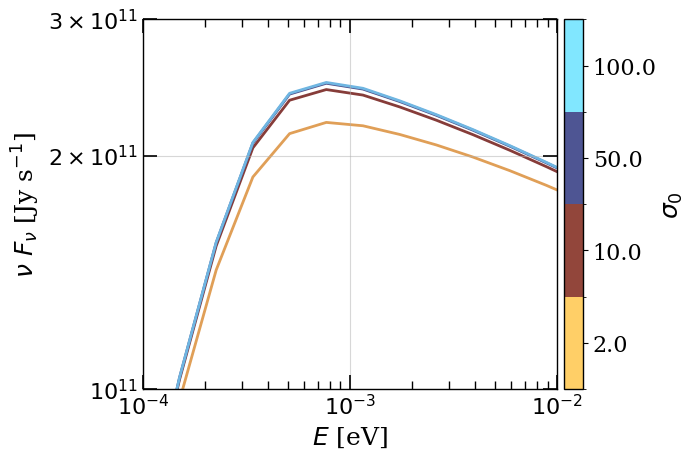

In [48]:
# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = len(sigma0s)
color_vector = np.linspace(0.1, 0.9, n)
colors = plt.cm.managua(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('managua', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Set labels
plt.title('')
plt.setp(ax, xlabel=r"$E$ [eV]")
plt.setp(ax, ylabel=r"$\nu~F_\nu$ [Jy s$^{-1}$]")

# Set plot scales
xmin, xmax = 10e-5, 0.01
ymin, ymax = 1e11, 3e11

plt.xlim(xmin, xmax)

plt.ylim(ymin, ymax)

lista=[2,2,2,2]#[8,6,4,2]
ls=['-','-','-','-']

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(E/eV, E/h*SEDs_sigma[i]*1e23*h, ls=ls[i], color=colors[i], linewidth=lista[i], label='', zorder=1)

plt.legend(loc='best')
ax.loglog() 

cbar = fig.colorbar(sm, ax=ax, ticks=c, label=r"$\sigma_0$", pad=0.015)
cbar.ax.set_yticklabels(sigma0s)  # vertically oriented colorbar

# Set xticks
# num = int(np.log10(xmax/xmin))
# x_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2))
# ax.xaxis.set_major_locator(x_major)
# x_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2) * 3)
# ax.xaxis.set_minor_locator(x_minor)
# ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_xticks([1e-4, 1e-3,1e-2])
ax.set_xticklabels([
    # r'$10^{-5}$',
    r'$10^{-4}$',
    r'$10^{-3}$',
    r'$10^{-2}$'
])



# Set yticks
ax.set_yticks([ 1e11, 2e11, 3e11])
ax.set_yticklabels([
    r'$10^{11}$',
    r'$2\times10^{11}$',
    r'$3\times10^{11}$'
])
# Minor ticks automáticos
ax.yaxis.set_minor_locator(matplotlib.ticker.LogLocator(base=10, subs='auto'))
# numy = int(np.log10(ymax/ymin))
# ax.yaxis.set_major_locator(plt.MaxNLocator(3))
# # y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = (numy//2)+1)
# # ax.yaxis.set_major_locator(y_major)
# y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (numy+2))
# ax.yaxis.set_minor_locator(y_minor)
# # ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())


# Ticks más largos, hacia adentro y espejados
ax.tick_params(axis='both', which='major',
               direction='in',
               length=10,      # longitud de ticks mayores
               width=1.2,
               top=True, right=True)

ax.tick_params(axis='both', which='minor',
               direction='in',
               length=6,      # longitud de ticks menores
               width=1.0,
               top=True, right=True)



plt.grid(alpha=0.5)
plt.legend('',frameon=False)
plt.show()

#fig.tight_layout(pad=0)
#fig.savefig('SEDs_etas.pdf', bbox_inches='tight', pad_inches = 0.01)
#AJUSTO A MANO EL RECORTE
fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.91)
fig.savefig('SEDs_sigma0s.pdf', bbox_inches='tight')

# Explore Ljet variations

In [12]:
# Make a list with the values of Lj 
Ljs = [1e41, 1e42, 1e43, 1e44] 

# Calculate the SED for each Lj (fixing default parameters)

SEDs_lj = []

for Lj in Ljs:
    
    print(f'{Lj=}')
    #SED = model_sed(E, z, sigma0, Lj, z0, a_inj)
    SED = model_syn(E, z, sigma0_def, Lj, z0_def, a_inj_def)
    time.sleep(2)
    SEDs_lj.append(SED)

Lj=1e+41
Lj=1e+42
Lj=1e+43
Lj=1e+44


### Grafico E*L [erg s-1] vs E [eV]

/tmp/ipykernel_19897/163985565.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('managua', n)
/tmp/ipykernel_19897/163985565.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='best')


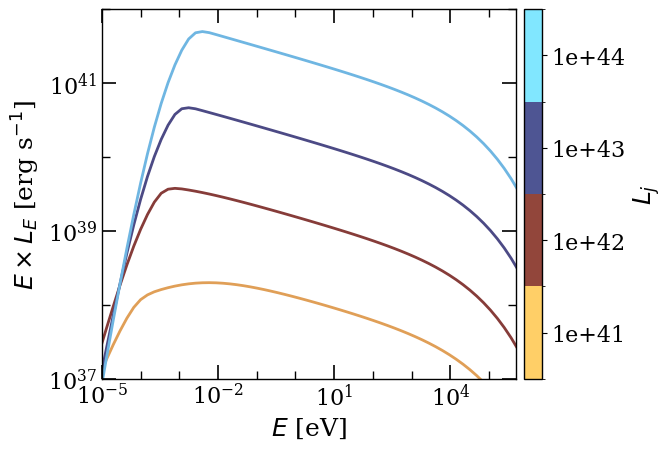

In [49]:
# Voy a graficar datos y modelo
matplotlib.rcParams['text.usetex'] = False
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = len(Ljs)
color_vector = np.linspace(0.1, 0.9, n)
colors = plt.cm.managua(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('managua', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Set labels
plt.title('')
plt.setp(ax, xlabel=r"$E$ [eV]")
plt.setp(ax, ylabel=r"$E \times L_E$ [erg s$^{-1}$]")

# Set plot scales
xmin, xmax = 1e-5,5e5#E_min/eV, E_max/eV
ymin, ymax = 1e37, 1e42
plt.xlim(xmin, xmax)
plt.ylim(ymin, ymax)

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(E/eV, E*SEDs_lj[i]*a, ls='-', color=colors[i], linewidth=2, label='', zorder=1)

plt.legend(loc='best')
ax.loglog() 

cbar = fig.colorbar(sm, ax=ax, ticks=c, label=r"$L_j$", pad=0.015)
cbar.ax.set_yticklabels(Ljs)  # vertically oriented colorbar

# Set xticks
num = int(np.log10(xmax/xmin))
x_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = num//2)
ax.xaxis.set_major_locator(x_major)
x_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2) * 3)
ax.xaxis.set_minor_locator(x_minor)
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# Set yticks
numy = int(np.log10(ymax/ymin))
y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy//2+1)
ax.yaxis.set_major_locator(y_major)
y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy+2)
ax.yaxis.set_minor_locator(y_minor)
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# Ticks más largos, hacia adentro y espejados
ax.tick_params(axis='both', which='major',
               direction='in',
               length=10,      # longitud de ticks mayores
               width=1.2,
               top=True, right=True)

ax.tick_params(axis='both', which='minor',
               direction='in',
               length=6,      # longitud de ticks menores
               width=1.0,
               top=True, right=True)



plt.legend('',frameon=False)
plt.show()

#fig.tight_layout(pad=0)
#fig.savefig('SEDs_etas.pdf', bbox_inches='tight', pad_inches = 0.01)
#AJUSTO A MANO EL RECORTE
fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.89)
fig.savefig('SEDs_Ljs.pdf', bbox_inches='tight')

### $\nu F_\nu$ [Jy Hz] vs $\nu$ [GHz]

/tmp/ipykernel_19897/2918025283.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('managua', n)
/tmp/ipykernel_19897/2918025283.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='best')


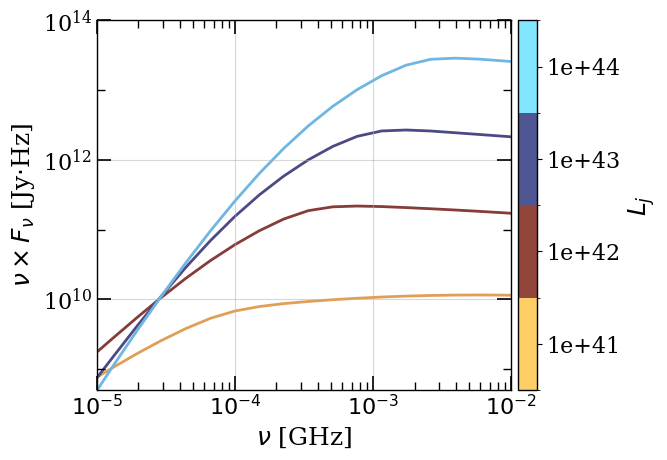

In [50]:
# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = len(Ljs)
color_vector = np.linspace(0.1, 0.9, n)
colors = plt.cm.managua(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('managua', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Set labels
plt.title('')
plt.setp(ax, xlabel=r"$\nu$ [GHz]")
plt.setp(ax, ylabel=r"$\nu \times F_\nu$ [Jy$\cdot$Hz]")

# Set plot scales
xmin, xmax = 1e-5, 0.01
# xmin, xmax = 10, 1000
# ymin, ymax = 1e9, 3e11

ymin, ymax = .5e9, 1e14

plt.xlim(xmin, xmax)

plt.ylim(ymin, ymax)


# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(E/eV, E/h*SEDs_lj[i]*1e23*h, ls='-', color=colors[i], linewidth=2, label='', zorder=1)

plt.legend(loc='best')
ax.loglog() 

cbar = fig.colorbar(sm, ax=ax, ticks=c, label=r"$L_j$", pad=0.015)
cbar.ax.set_yticklabels(Ljs)  # vertically oriented colorbar

# Set xticks
# num = int(np.log10(xmax/xmin))
# x_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = num//2)
# ax.xaxis.set_major_locator(x_major)
# x_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2) * 3)
# ax.xaxis.set_minor_locator(x_minor)
# ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

ax.set_xticks([ 1e-5,1e-4, 1e-3,1e-2])
ax.set_xticklabels([
    r'$10^{-5}$',
    r'$10^{-4}$',
    r'$10^{-3}$',
    r'$10^{-2}$'
])


# Set yticks
numy = int(np.log10(ymax/ymin))
y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy//2+1)
ax.yaxis.set_major_locator(y_major)
y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy+2)
ax.yaxis.set_minor_locator(y_minor)
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# Ticks más largos, hacia adentro y espejados
ax.tick_params(axis='both', which='major',
               direction='in',
               length=10,      # longitud de ticks mayores
               width=1.2,
               top=True, right=True)

ax.tick_params(axis='both', which='minor',
               direction='in',
               length=6,      # longitud de ticks menores
               width=1.0,
               top=True, right=True)


plt.grid(alpha=0.5)
plt.legend('',frameon=False)
plt.show()

#fig.tight_layout(pad=0)
#fig.savefig('SEDs_etas.pdf', bbox_inches='tight', pad_inches = 0.01)
#AJUSTO A MANO EL RECORTE
fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.89)
fig.savefig('SEDs_Ljs_Fnu.pdf', bbox_inches='tight')

# Explore z0 variations

In [ ]:
# # Make a list with the values of z0
# z0s = [5,50, 100, 250, 350]

# # Calculate the SED for each z0 (fixing default parameters)
# SEDs_z0 = []
# for z0 in z0s:
#     print(f'{z0=}')
#     #SED = model_sed(E, z, sigma0, Lj, z0, a_inj)
#     SED = model_syn(E, z, sigma0_def, Lj_def, z0*R_g, a_inj_def)
#     time.sleep(2)
#     SEDs_z0.append(SED)

### Grafico E*L [erg s-1] vs E [eV]

In [ ]:
# # Voy a graficar datos y modelo
# fig, ax = plt.subplots(1)

# # Defino una paleta discreta
# n = len(z0s)
# color_vector = np.linspace(0.1, 0.9, n)
# colors = plt.cm.copper_r(color_vector) # define a palette avoiding extreme colors
# # Genero una colorbar discreta para n puntos
# c = np.arange(1, n+1) 
# cmap = plt.cm.get_cmap('copper_r', n)
# norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
# sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# # Set labels
# plt.title('')
# plt.setp(ax, xlabel=r"$E$ [eV]")
# plt.setp(ax, ylabel=r"$E \times L_E$ [erg s$^{-1}$]")

# # Set plot scales
# xmin, xmax = 1e-4,1e4#E_min/eV, E_max/eV
# ymin, ymax = 1e40, 3.3e41
# plt.xlim(xmin, xmax)
# plt.ylim(ymin, ymax)

# # Grafico las funciones individuales y su suma usando una paleta discreta
# for i in range(n):
#     plt.plot(E/eV, E*SEDs_z0[i]*a, ls='-', color=colors[i], linewidth=2, label='', zorder=1)

# plt.legend(loc='best')
# ax.loglog() 

# cbar = fig.colorbar(sm, ax=ax, ticks=c, label=r"$z_0 [R_g]$ ", pad=0.015)
# cbar.ax.set_yticklabels(z0s)  # vertically oriented colorbar

# # Set xticks
# num = int(np.log10(xmax/xmin))
# x_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = num//2)
# ax.xaxis.set_major_locator(x_major)
# x_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2) * 3)
# ax.xaxis.set_minor_locator(x_minor)
# ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# # Set yticks
# numy = int(np.log10(ymax/ymin))
# y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy//2+1)
# ax.yaxis.set_major_locator(y_major)
# y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy+2)
# ax.yaxis.set_minor_locator(y_minor)
# ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# plt.legend('',frameon=False)
# plt.show()

# #fig.tight_layout(pad=0)
# #fig.savefig('SEDs_etas.pdf', bbox_inches='tight', pad_inches = 0.01)
# #AJUSTO A MANO EL RECORTE
# fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.96)
# fig.savefig('SEDs_z0s.pdf')

### $\nu F_\nu$ [Jy Hz] vs $\nu$ [GHz]

In [ ]:
# #Grafico anterior en \nu vs \nu*F_\nu
# # Voy a graficar datos y modelo
# fig, ax = plt.subplots(1)

# # Defino una paleta discreta
# n = len(z0s)
# color_vector = np.linspace(0.1, 0.9, n)
# colors = plt.cm.managua(color_vector) # define a palette avoiding extreme colors
# # Genero una colorbar discreta para n puntos
# c = np.arange(1, n+1) 
# cmap = plt.cm.get_cmap('managua', n)
# norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
# sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# # Set labels
# plt.title('')
# plt.setp(ax, xlabel=r"$\nu$ [GHz]")
# plt.setp(ax, ylabel=r"$\nu \times F_\nu$ [Jy$\cdot$Hz]")

# # Set plot scales
# xmin, xmax = 1e1,1e11#E_min/eV, E_max/eV
# ymin, ymax = 1e10, 1e12

# plt.xlim(xmin, xmax)

# plt.ylim(ymin, ymax)

# lista=[12,8,6,4,1]
# ls=['--','-','--','-','--']

# # Grafico las funciones individuales y su suma usando una paleta discreta
# for i in range(n):
#     plt.plot(E/h/1e9, E/h*SEDs_z0[i]*1e23*h, ls=ls[i], color=colors[i], linewidth=lista[i], label='', zorder=1)

# plt.legend(loc='best')
# ax.loglog() 

# cbar = fig.colorbar(sm, ax=ax, ticks=c, label=r"$z_0 [R_g]$ ", pad=0.015)
# cbar.ax.set_yticklabels(z0s)  # vertically oriented colorbar

# # Set xticks
# num = int(np.log10(xmax/xmin))
# x_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = num//2)
# ax.xaxis.set_major_locator(x_major)
# x_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2) * 3)
# ax.xaxis.set_minor_locator(x_minor)
# ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# # Set yticks
# numy = int(np.log10(ymax/ymin))
# y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy//2+1)
# ax.yaxis.set_major_locator(y_major)
# y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy+2)
# ax.yaxis.set_minor_locator(y_minor)
# ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# plt.legend('',frameon=False)
# plt.show()

# #fig.tight_layout(pad=0)
# #fig.savefig('SEDs_etas.pdf', bbox_inches='tight', pad_inches = 0.01)
# #AJUSTO A MANO EL RECORTE
# fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.96)
# fig.savefig('SEDs_z0s.pdf')

# Explore a_inj variations

In [36]:
# Make a list with the values of a_inj 
a_injs = [0.01, 0.5, 0.99, 1.5] 
a_inj_labels = [0.0, 0.5, 1.0, 1.5] 

# Calculate the SED for each a_inj (fixing default parameters)
SEDs_a = []
for a_inj in a_injs:
    print(f'{a_inj=}')
    time.sleep(1)
    #SED = model_sed(E, z, sigma0, Lj, z0, a_inj)
    SED = model_syn(E, z, sigma0_def, Lj_def, z0_def, a_inj)
    time.sleep(2)
    SEDs_a.append(SED)

a_inj=0.01
a_inj=0.5
a_inj=0.99
a_inj=1.5


### Grafico E*L [erg s-1] vs E [eV]

/tmp/ipykernel_19897/3583901308.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('managua', n)
/tmp/ipykernel_19897/3583901308.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='best')


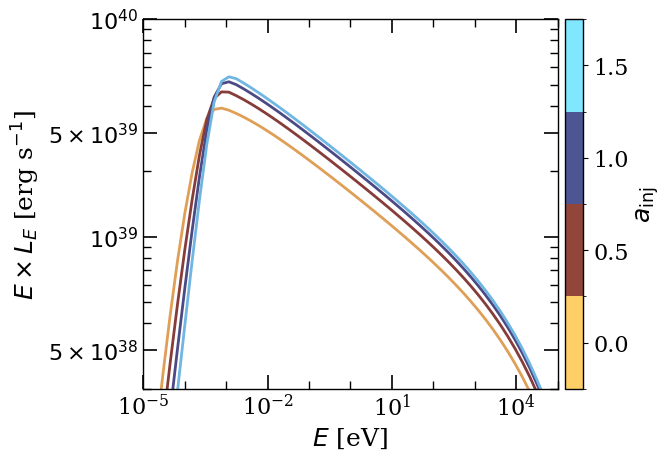

In [51]:
# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = len(a_injs)
color_vector = np.linspace(0.1, 0.9, n)
colors = plt.cm.managua(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('managua', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Set labels
plt.title('')
plt.setp(ax, xlabel=r"$E$ [eV]")
plt.setp(ax, ylabel=r"$E \times L_E$ [erg s$^{-1}$]")

# Set plot scales
xmin, xmax = 1e-5, 1e5#E_min/eV, E_max/eV
ymin, ymax = 2e38, 1e40
plt.xlim(xmin, xmax)

plt.ylim(ymin, ymax)

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(E/eV, E*SEDs_a[i]*a, ls='-', color=colors[i], linewidth=2, label='', zorder=1)

plt.legend(loc='best')
ax.loglog() 

cbar = fig.colorbar(sm, ax=ax, ticks=c, label=r"$a_\mathrm{inj}$", pad=0.015)
cbar.ax.set_yticklabels(a_inj_labels)  # vertically oriented colorbar

# Set xticks
num = int(np.log10(xmax/xmin))
x_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = num//2)
ax.xaxis.set_major_locator(x_major)
x_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2) * 3)
ax.xaxis.set_minor_locator(x_minor)
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# Set yticks
ax.set_yticks([ 3e38,1e39, 3e39,1e40])
ax.set_yticklabels([
    r'$5\times10^{38}$',
    r'$10^{39}$',
    r'$5\times10^{39}$',
    r'$10^{40}$'
])

# # Set yticks
# numy = int(np.log10(ymax/ymin))
# y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy//2+1)
# ax.yaxis.set_major_locator(y_major)
# y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy+2)
# ax.yaxis.set_minor_locator(y_minor)
# ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# Ticks más largos, hacia adentro y espejados
ax.tick_params(axis='both', which='major',
               direction='in',
               length=10,      # longitud de ticks mayores
               width=1.2,
               top=True, right=True)

ax.tick_params(axis='both', which='minor',
               direction='in',
               length=6,      # longitud de ticks menores
               width=1.0,
               top=True, right=True)



plt.legend('',frameon=False)
plt.show()

#fig.tight_layout(pad=0)
#fig.savefig('SEDs_etas.pdf', bbox_inches='tight', pad_inches = 0.01)
#AJUSTO A MANO EL RECORTE
fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.97)
fig.savefig('SEDs_a_injs.pdf', bbox_inches='tight')

### $\nu F_\nu$ [Jy Hz] vs $\nu$ [GHz]

/tmp/ipykernel_19897/3102181874.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('managua', n)
/tmp/ipykernel_19897/3102181874.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='best')


[0.5 1.5 2.5 3.5 4.5]


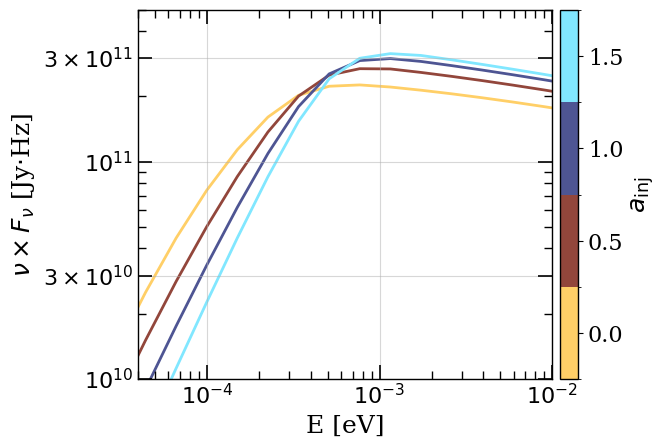

In [52]:
#Grafico anterior en \nu vs \nu*F_\nu


# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = len(a_injs)
color_vector = np.linspace(0, 1, n)
colors = plt.cm.managua(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('managua', n)
print(np.arange(n+1)+0.5)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Set labels
plt.title('')
plt.setp(ax, xlabel=r"E [eV]")
plt.setp(ax, ylabel=r"$\nu \times F_\nu$ [Jy$\cdot$Hz]")

# Set plot scales
# xmin, xmax = 5e0,1e11#E_min/eV, E_max/eV
xmin, xmax = 4e-5, 0.004
ymin, ymax = 1e10, .5e12
plt.xlim(xmin, xmax)

plt.ylim(ymin, ymax)

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(E/eV, E/h*SEDs_a[i]*1e23*h, ls='-', color=colors[i], linewidth=2, label='', zorder=1)

plt.legend(loc='best')
ax.loglog() 

cbar = fig.colorbar(sm, ax=ax, ticks=c, label=r"$a_\mathrm{inj}$", pad=0.015)
cbar.ax.set_yticklabels(a_inj_labels)  # vertically oriented colorbar

# Set xticks
# num = int(np.log10(xmax/xmin))
# x_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = num//2)
# ax.xaxis.set_major_locator(x_major)
# x_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2) * 3)
# ax.xaxis.set_minor_locator(x_minor)
# ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_xticks([ 1e-4, 1e-3,1e-2])
ax.set_xticklabels([
    r'$10^{-4}$',
    r'$10^{-3}$',
    r'$10^{-2}$'
])

# Set yticks
ax.set_yticks([ 1e10,3e10,1e11, 3e11])
ax.set_yticklabels([
    r'$10^{10}$',
    r'$3\times10^{10}$',
    r'$10^{11}$',
    
    r'$3\times10^{11}$'
])

# # Set yticks
# numy = int(np.log10(ymax/ymin))
# y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy//2+1)
# ax.yaxis.set_major_locator(y_major)
# y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy+2)
# ax.yaxis.set_minor_locator(y_minor)
# ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# Ticks más largos, hacia adentro y espejados
ax.tick_params(axis='both', which='major',
               direction='in',
               length=10,      # longitud de ticks mayores
               width=1.2,
               top=True, right=True)

ax.tick_params(axis='both', which='minor',
               direction='in',
               length=6,      # longitud de ticks menores
               width=1.0,
               top=True, right=True)


plt.grid(alpha=0.5)
plt.legend('',frameon=False)
plt.show()

#fig.tight_layout(pad=0)
#fig.savefig('SEDs_etas.pdf', bbox_inches='tight', pad_inches = 0.01)
#AJUSTO A MANO EL RECORTE
fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.97)
fig.savefig('SEDs_a_injs_Fnu.pdf', bbox_inches='tight')